In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import r2_score

In [2]:
boston = fetch_openml(data_id=531, as_frame=True)

X = boston.data.astype(float)
y = boston.target.astype(float)

df = X.copy()
df['MEDV'] = y

display(df.head())
print("Dataset shape:", df.shape)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


Dataset shape: (506, 14)


In [3]:
df.info()

display(df.isnull().sum())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB


CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 404
Test rows: 102


In [5]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [6]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
r2 = r2_score(y_test, y_pred)

print("Test MSE:", round(mse, 4))
print("Test RMSE (thousand dollars):", round(rmse, 4))
print("Test MAE (thousand dollars):", round(mae, 4))
print("Test MAPE (%):", round(mape, 2))
print("Test R²:", round(r2, 4))

Test MSE: 7.8802
Test RMSE (thousand dollars): 2.8072
Test MAE (thousand dollars): 2.0367
Test MAPE (%): 11.09
Test R²: 0.8925


مدل ۱۰۰ درختی روی داده‌های تست، RMSE حدود ۲۸۰۷ دلار و MAE حدود ۲۰۳۷ دلار داشته؛ یعنی میانگین اختلاف مطلق پیش‌بینی‌ها با مقدار واقعی حدود ۲۰۳۷ دلار بوده. خطای درصدی MAPE هم حدود ۱۱٫۰۹٪ شده. مقدار R² برابر با ۰٫۸۹۲۵ نشون می‌ده مدل حدود ۸۹٫۲۵٪ از تغییرات مقدار هدف در داده‌های تست رو توضیح داده.

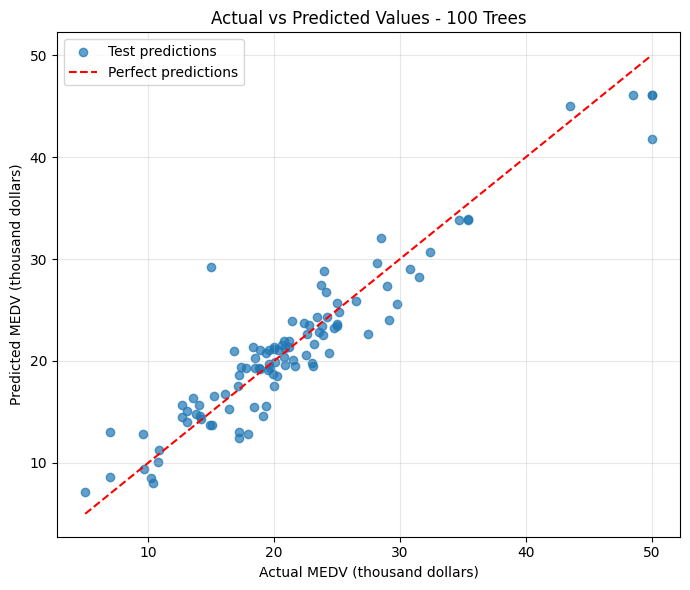

In [7]:
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7,
    label='Test predictions'
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    linestyle='--',
    label='Perfect predictions'
)

plt.title('Actual vs Predicted Values - 100 Trees')
plt.xlabel('Actual MEDV (thousand dollars)')
plt.ylabel('Predicted MEDV (thousand dollars)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

بیشتر نقطه‌ها نزدیک خط قرمز قرار گرفتن، پس پیش‌بینی‌های مدل در بیشتر موارد به مقدار واقعی نزدیک بودن. بااین‌حال، چند نقطه فاصله بیشتری از خط دارن و در مقادیر واقعی نزدیک ۵۰ هزار دلار، مدل عمدتاً مقدار کمتری پیش‌بینی کرده. بنابراین مدل روند کلی رو خوب یاد گرفته، ولی خطاش برای همه نمونه‌ها یکسان نیست.

In [8]:
results = []

for n in [50, 100, 200]:

    if n == 100:
        test_rmse = rmse
        test_r2 = r2

    else:
        forest = RandomForestRegressor(
            n_estimators=n,
            random_state=42
        )

        forest.fit(X_train, y_train)

        predictions = forest.predict(X_test)

        test_rmse = np.sqrt(
            mean_squared_error(y_test, predictions)
        )
        test_r2 = r2_score(y_test, predictions)

    results.append({
        'Number of trees': n,
        'Test RMSE (thousand dollars)': test_rmse,
        'Test R²': test_r2
    })

comparison = pd.DataFrame(results)

display(comparison.round(4))

,Number of trees,Test RMSE (thousand dollars),Test R²
0,50,2.7480,0.8970
1,100,2.8072,0.8925
2,200,2.9316,0.8828


In [9]:
comparison['Test RMSE (dollars)'] = (
    comparison['Test RMSE (thousand dollars)'] * 1000
)

display(comparison.round(4))

,Number of trees,Test RMSE (thousand dollars),Test R²,Test RMSE (dollars)
0,50,2.7480,0.8970,2747.9594
1,100,2.8072,0.8925,2807.1725
2,200,2.9316,0.8828,2931.5591


بین سه مدل بررسی‌شده، جنگل ۵۰ درختی با RMSE حدود ۲٫۷۴۸ هزار دلار و R² برابر با ۰٫۸۹۷، بهترین نتیجه رو روی همین مجموعه تست داشته. با افزایش تعداد درخت‌ها به ۱۰۰ و ۲۰۰، خطای تست کمی بیشتر شده؛ پس در این آزمایش، بیشترشدن تعداد درخت‌ها باعث بهترشدن نتیجه نشده. البته از این مقایسه نمی‌شه نتیجه گرفت که ۵۰ درخت در همه تقسیم‌بندی‌های داده بهترین انتخابه.

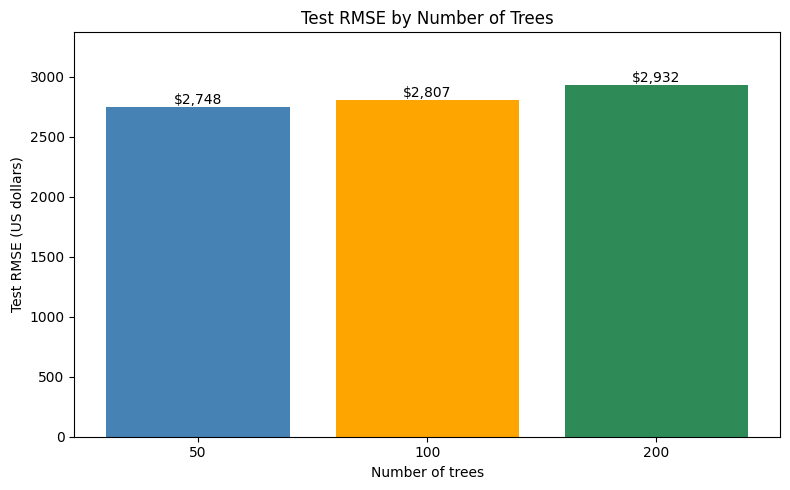

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Number of trees'].astype(str),
    comparison['Test RMSE (dollars)'],
    color=['steelblue', 'orange', 'seagreen']
)

for i in range(len(comparison)):
    value = comparison.loc[i, 'Test RMSE (dollars)']

    plt.text(
        i,
        value,
        f'${value:,.0f}',
        ha='center',
        va='bottom'
    )

plt.title('Test RMSE by Number of Trees')
plt.xlabel('Number of trees')
plt.ylabel('Test RMSE (US dollars)')
plt.ylim(0, comparison['Test RMSE (dollars)'].max() * 1.15)
plt.tight_layout()
plt.show()

چون واحد قیمت در دیتاست هزار دلاره، برای تبدیل RMSE به دلار اون رو در ۱۰۰۰ ضرب کردم. خطای مدل‌های ۵۰، ۱۰۰ و ۲۰۰ درختی به‌ترتیب حدود ۲۷۴۸، ۲۸۰۷ و ۲۹۳۲ دلار شده. نمودار هم نشون می‌ده مدل ۵۰ درختی در این مقایسه کمترین RMSE رو داشته.